# Week 2 · Lab Workshop
## Your personal filter & glitch series
*AI for Creativity · Level 6 · work in pairs*

**Brief:** build a signature image filter and produce a **series of 5 glitch images** from your own photos or artworks, ready for a mini-exhibition.

| Track | What you do |
|---|---|
| 🟢 **Core** | Combine the provided effects into `my_filter(img)` and apply it to 3 images |
| 🔵 **Stretch** | Invent a new effect with a *strength* parameter (pixel sort by threshold, 5-colour quantise, or mosaic) |

**How to use this notebook**

- Works in **Google Colab** (open via *File → Upload notebook*) and in **Jupyter Notebook / JupyterLab** (Anaconda).
- Run a cell with **Shift + Enter**. Run cells **top to bottom** — later cells use things made in earlier ones.
- Grey text starting with `#` is a *comment*: a note for humans. Python ignores it.
- Broke something? *Runtime → Restart* (Colab) or *Kernel → Restart* (Jupyter) and run from the top. You cannot break the computer.

## Setup — run this cell (tools from the demo)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def load_image(path=None, max_side=600):
    """Load an image as a NumPy array (height x width x 3).
    No path? We use a sample photo of a cat from scikit-image."""
    if path:
        img = Image.open(path).convert("RGB")
    else:
        from skimage import data
        img = Image.fromarray(data.chelsea())
    img.thumbnail((max_side, max_side))
    return np.array(img)

def show(*images, titles=None):
    """Show one or more images side by side."""
    fig, axes = plt.subplots(1, len(images), figsize=(5 * len(images), 5))
    axes = np.atleast_1d(axes)
    for i, (ax, im) in enumerate(zip(axes, images)):
        ax.imshow(im, cmap="gray" if im.ndim == 2 else None)
        ax.set_title(titles[i] if titles else "")
        ax.axis("off")
    plt.show()

def invert(img):
    return 255 - img

def swap_channels(img, order=(2, 0, 1)):
    return img[:, :, list(order)]

def greyscale(img):
    grey = 0.299 * img[:, :, 0] + 0.587 * img[:, :, 1] + 0.114 * img[:, :, 2]
    return grey.astype(np.uint8)

def add_noise(img, amount=40):
    noise = np.random.randint(-amount, amount + 1, img.shape)
    return np.clip(img.astype(int) + noise, 0, 255).astype(np.uint8)

def row_shift_glitch(img, strength=40, band_height=12):
    out = img.copy()
    for top in range(0, img.shape[0], band_height):
        shift = np.random.randint(-strength, strength + 1)
        out[top:top + band_height] = np.roll(out[top:top + band_height], shift, axis=1)
    return out

**Using your own image**
- *Colab:* click the folder icon on the left → upload → then use `load_image("yourfile.jpg")`.
- *Jupyter:* put the image in the same folder as this notebook → `load_image("yourfile.jpg")`.
- No image yet? `load_image()` gives you a sample cat photo.

## 🟢 Core · Step 1 — Load 3 images

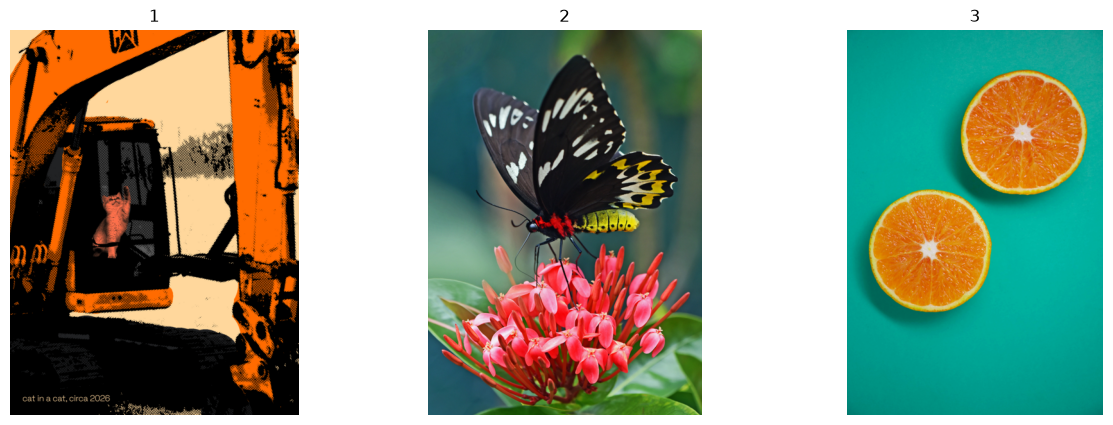

In [2]:
img1 = load_image("akg-cat.png")    # Replace with load_image("photo1.jpg")
img2 = load_image("butterfly.jpg")  # Replace with load_image("photo2.jpg")
img3 = load_image("orange.jpg")     # Replace with load_image("photo3.jpg")
show(img1, img2, img3, titles=["1", "2", "3"])

## 🟢 Core · Step 2 — Design `my_filter`
Combine **at least three** effects. The *order* matters — experiment!

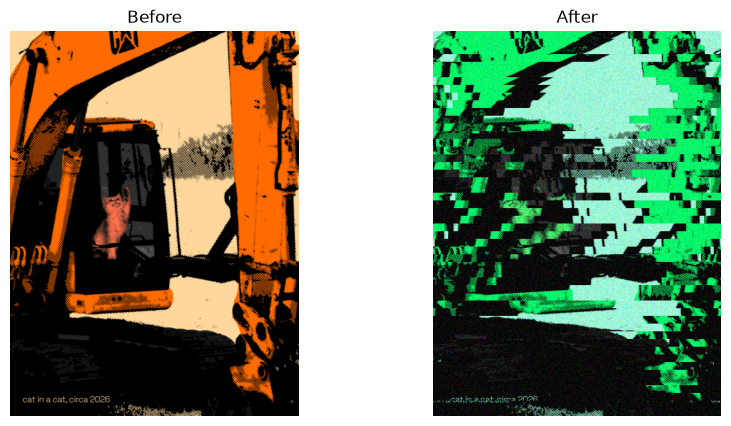

In [3]:
def my_filter(img):
    step1 = swap_channels(img)        # e.g. add_noise(img, 30)
    step2 = add_noise(step1)          # e.g. swap_channels(step1)
    step3 = row_shift_glitch(step2)   # e.g. row_shift_glitch(step2, strength=40)
    return step3

show(img1, my_filter(img1), titles=["Before", "After"])

## 🟢 Core · Step 3 — Apply to all three and save

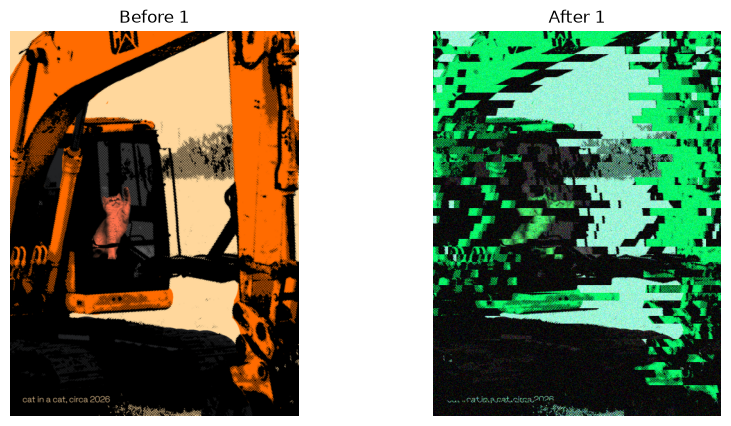

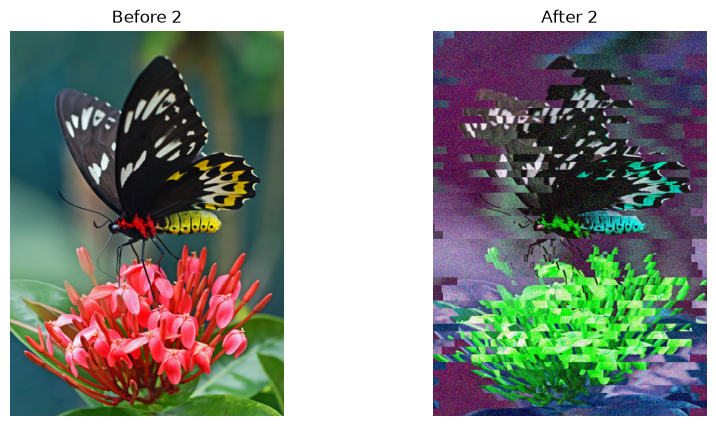

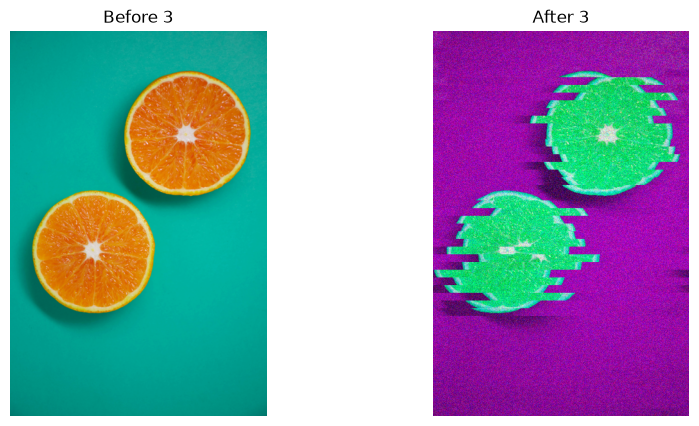

In [4]:
for i, im in enumerate([img1, img2, img3], start=1):
    out = my_filter(im)
    Image.fromarray(out).save(f"my_filter_{i}.png")
    show(im, out, titles=[f"Before {i}", f"After {i}"])

## 🟢 Core · Step 4 — A glitch series of 5
Randomness makes every run different. Generate 5 and keep them all — curation is part of the art.

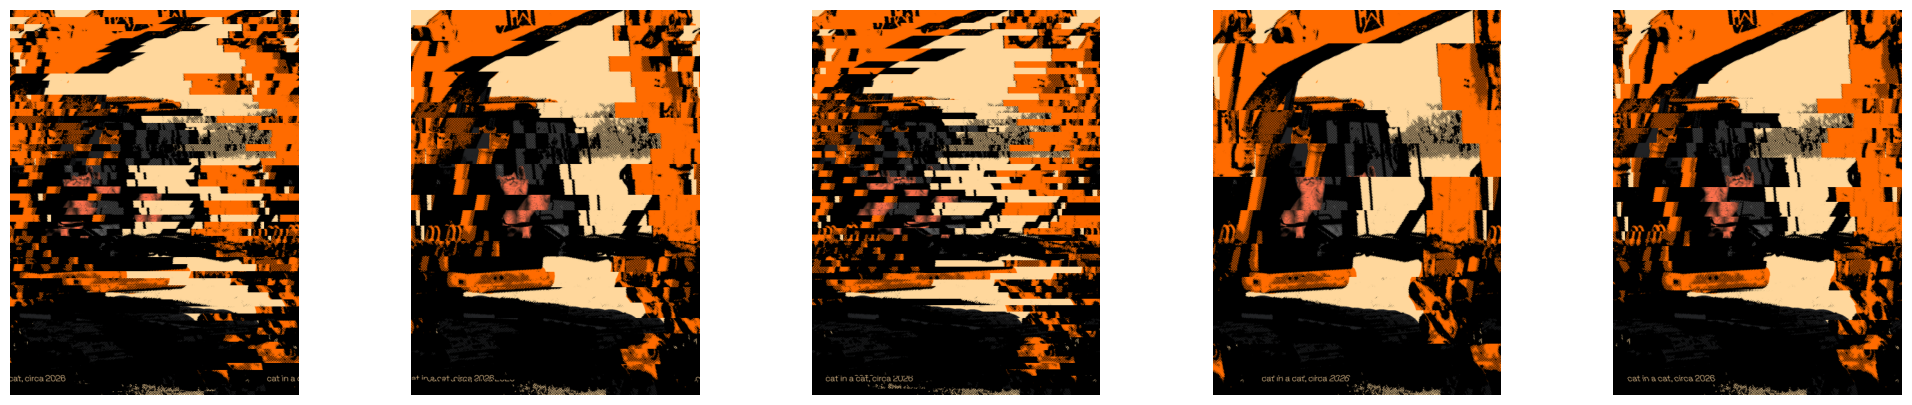

In [5]:
from random import randint

series = [
    row_shift_glitch(
        img1,
        strength=randint(15, 80),
        band_height=randint(8, 60)
    ) for _ in range(5)
]

show(*series)
for i, im in enumerate(series, start=1):
    Image.fromarray(im).save(f"glitch_series_{i}.png")

✅ **Core done!** Put the before/after pairs in your R&D journal with a 300-word reflection: *what did each effect do to the numbers, and what did it do to the feeling of the image?*

---
## 🔵 Stretch · Invent an effect
Choose one (or more) and give it a `strength` parameter:

1. **Threshold pixel sort** — only sort pixels brighter than `threshold` in each row.
2. **Colour quantise** — reduce the image to `n` colours. Hint: `Image.fromarray(img).quantize(colors=n).convert("RGB")`.
3. **Mosaic** — shrink the image by `block` times, then enlarge it with `Image.NEAREST`.

[143 120 104]


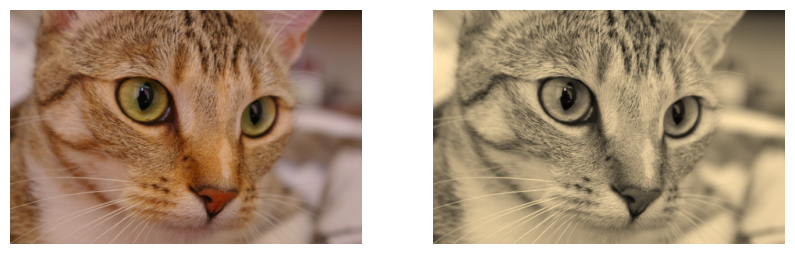

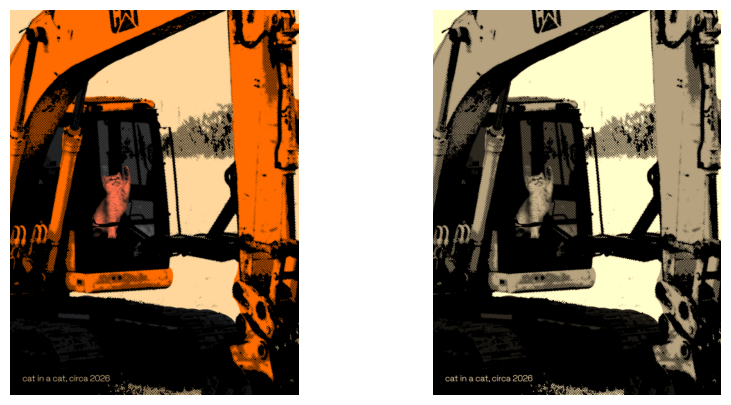

In [14]:
def sepia_filter(img):
    """Applies a sepia filter onto the image array"""

    # This formula comes from https://leware.net/photo/blogSepia.html
    sepia_matrix = np.array([
        [0.393, 0.769, 0.189],
        [0.349, 0.686, 0.168],
        [0.272, 0.534, 0.131]
    ])

    # Multiply the matrix onto the image's original RGB values
    # `np.clip()` ensures that the values remain within the range 0 to 255
    sepia_image = np.clip(img @ sepia_matrix.T, 0, 255)
    return sepia_image.astype(np.uint8)

# Little demonstration of the filter
stock = load_image()

show(stock, sepia_filter(stock))
show(img1, sepia_filter(img1))
